# CNN 精細分類器 — HRIPCB
### `notebooks/02_dl_classification.ipynb` · pcb-aoi · Stage 2

Stage 1 的傳統 CV 在 registration 與 localization 表現良好,但**精細分類撞上
hand-crafted feature 的天花板**(mAP@0.5 僅 27.4%,小缺陷 AP 2–5%)。Stage 2 用
CNN 解決分類問題。

**核心架構(R-CNN 風格的兩階段合作)**:沿用 Stage 1 的 **region proposals**
作為 crop 來源,交給 ImageNet 預訓練的 **ResNet18** 做 6 類精細分類 —— 展示
「兩階段合作」,而非兩個獨立方法。

程式:[`src/dataset.py`](../src/dataset.py)、
[`src/dl_classifier.py`](../src/dl_classifier.py)、
[`src/train_classifier.py`](../src/train_classifier.py)、
[`src/evaluate_classifier.py`](../src/evaluate_classifier.py)。

## 1. 資料準備

* **crop 來源**:GT bbox(訓練)或 Stage 1 proposals(end-to-end 評估)
* **padding**:bbox 周圍補 30% 上下文(CNN 需看周圍 PCB 環境),resize 224×224
* **split**:以 **image 為單位** 70/15/15(避免同張圖的 bbox 跨 split 洩漏),
  依類別分層,固定 `seed=42` → train 483 / val 102 / test 108 張影像
* **增強**:訓練用 random flip / rotation ±15° / colour jitter

下圖為每類 2 張典型 crops:

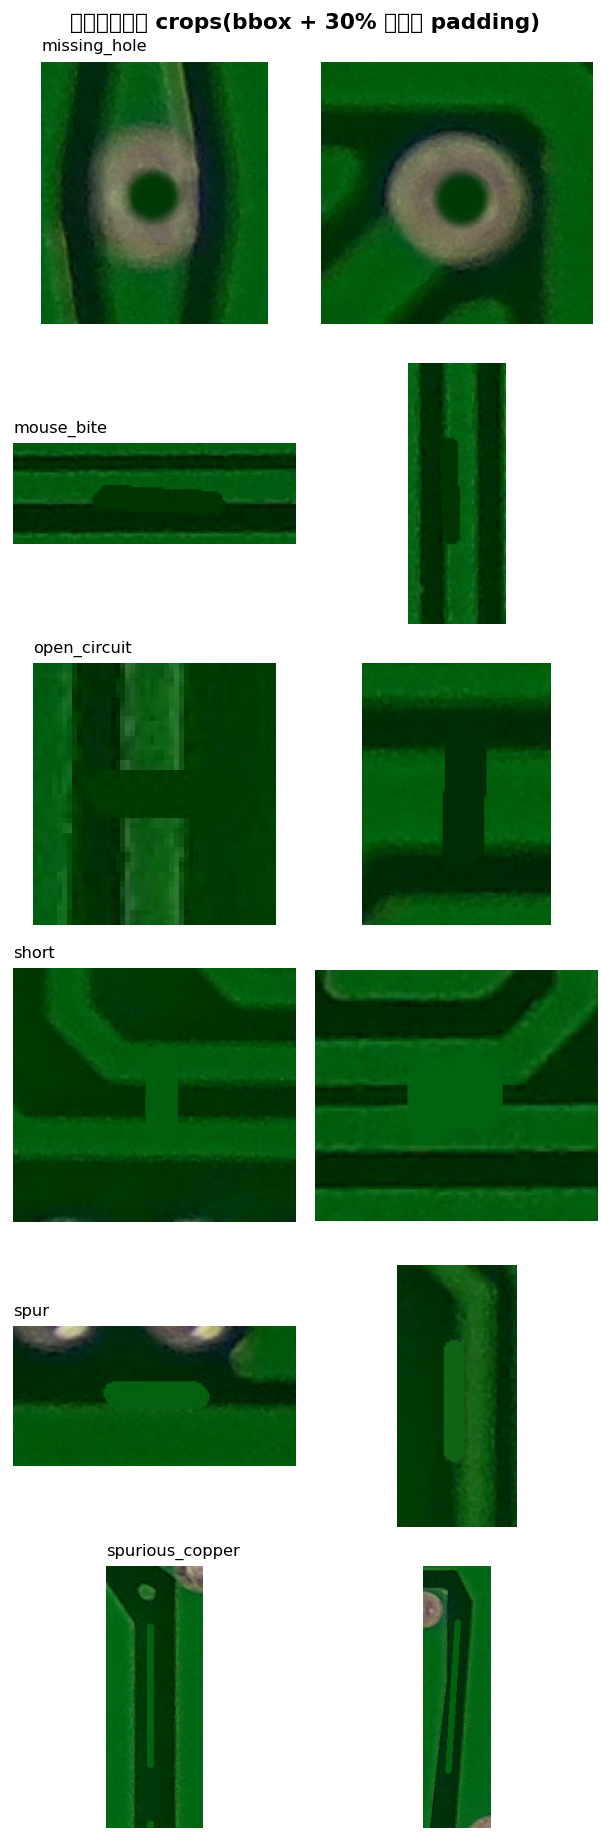

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd() / "02_dl_classification.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path(r"D:\ash-portfolio\pcb-aoi")
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
import pandas as pd
from src.hripcb import CLASSES, CLASS_ZH
FIG = ROOT / "results" / "figures"
display(Image(filename=str(FIG / "02_sample_crops_per_class.png")))

## 2. 模型:ResNet18 + ImageNet 遷移學習

以 `torchvision.models.resnet18(weights=IMAGENET1K_V1)` 初始化,將最後 `fc` 換成
6 類輸出,微調整個網路。遷移學習的邏輯:ImageNet 預訓練的低層濾波器(邊緣、紋理)
對 PCB 缺陷同樣適用,資料量(~2000 crops)不足以從零訓練,微調可快速收斂。

* Optimizer: Adam(lr=1e-4) · Loss: CrossEntropy
* Scheduler: ReduceLROnPlateau(val loss) · Early stopping: patience=10
* Batch 64 · 最多 50 epochs

## 3. 訓練過程

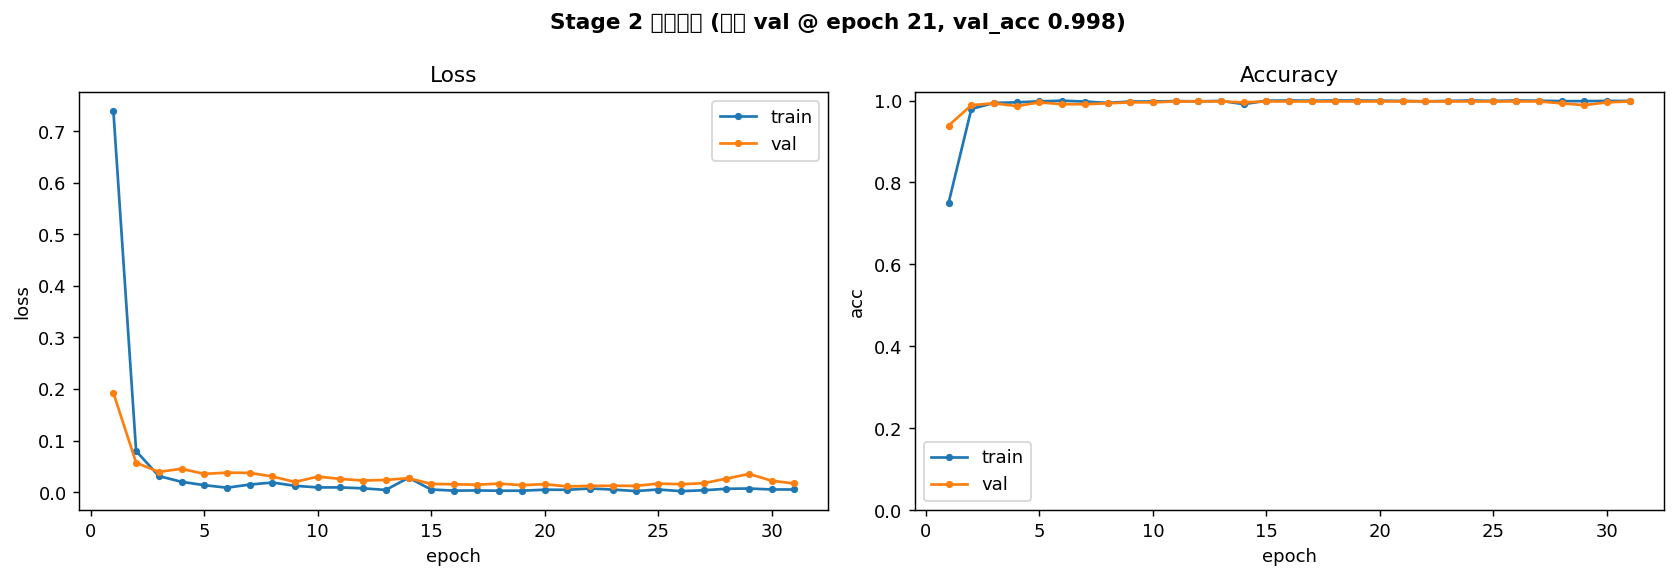

In [2]:
display(Image(filename=str(FIG / "02_training_curves.png")))

## 4. 評估:GT crops(上限)vs End-to-end(實戰)

**兩種評估對比是本階段的重點** —— 看出 CNN 分類能力的上限,以及實戰中受
Stage 1 proposal 品質的限制。End-to-end 用 **同一批 Stage 1 proposals**,只替換
分類器,直接對比 rule-based 與 CNN。

In [3]:
res = json.loads((ROOT / "results" / "classifier_eval_summary.json").read_text())
gt = res["gt_crops"]; e2e = res["end_to_end"]
summary = pd.DataFrame([
    {"評估模式": "GT crops(分類上限)", "Accuracy": f"{gt['accuracy']*100:.1f}%", "mAP@0.5": "n/a"},
    {"評估模式": "End-to-end:Stage1 proposals + rule-based", "Accuracy": "n/a",
     "mAP@0.5": f"{e2e['stage1']['mAP@0.5']*100:.1f}%"},
    {"評估模式": "End-to-end:Stage1 proposals + CNN", "Accuracy": "n/a",
     "mAP@0.5": f"{e2e['cnn']['mAP@0.5']*100:.1f}%"},
])
print(f"Stage 1 baseline(全資料集)= 27.4%  →  Stage 2 CNN end-to-end = {e2e['cnn']['mAP@0.5']*100:.1f}%")
summary

Stage 1 baseline(全資料集)= 27.4%  →  Stage 2 CNN end-to-end = 84.8%


,評估模式,Accuracy,mAP@0.5
0,GT crops(分類上限),100.0%,n/a
1,End-to-end:Stage1 proposals + rule-based,n/a,29.3%
2,End-to-end:Stage1 proposals + CNN,n/a,84.8%


In [4]:
# per-class:GT crops F1 與 end-to-end AP(Stage1 vs CNN)
rows = []
for c in CLASSES:
    rows.append({"class": c, "中文": CLASS_ZH[c],
                 "GT crops F1": round(gt["per_class"][c]["f1"], 3),
                 "S1 AP": round(e2e["stage1"]["per_class"][c]["ap"], 3),
                 "CNN AP": round(e2e["cnn"]["per_class"][c]["ap"], 3),
                 "Δ AP": round(e2e["cnn"]["per_class"][c]["ap"] - e2e["stage1"]["per_class"][c]["ap"], 3)})
pd.DataFrame(rows)

,class,中文,GT crops F1,S1 AP,CNN AP,Δ AP
0,missing_hole,缺孔,1.0,0.861,0.939,0.078
1,mouse_bite,鼠咬(缺口),1.0,0.026,0.948,0.921
2,open_circuit,斷路,1.0,0.059,0.941,0.882
3,short,短路,1.0,0.197,0.362,0.165
4,spur,毛刺(凸尖),1.0,0.004,0.912,0.908
5,spurious_copper,多餘銅(殘銅),1.0,0.610,0.983,0.373


### 4.1 GT crops 混淆矩陣(純分類能力)

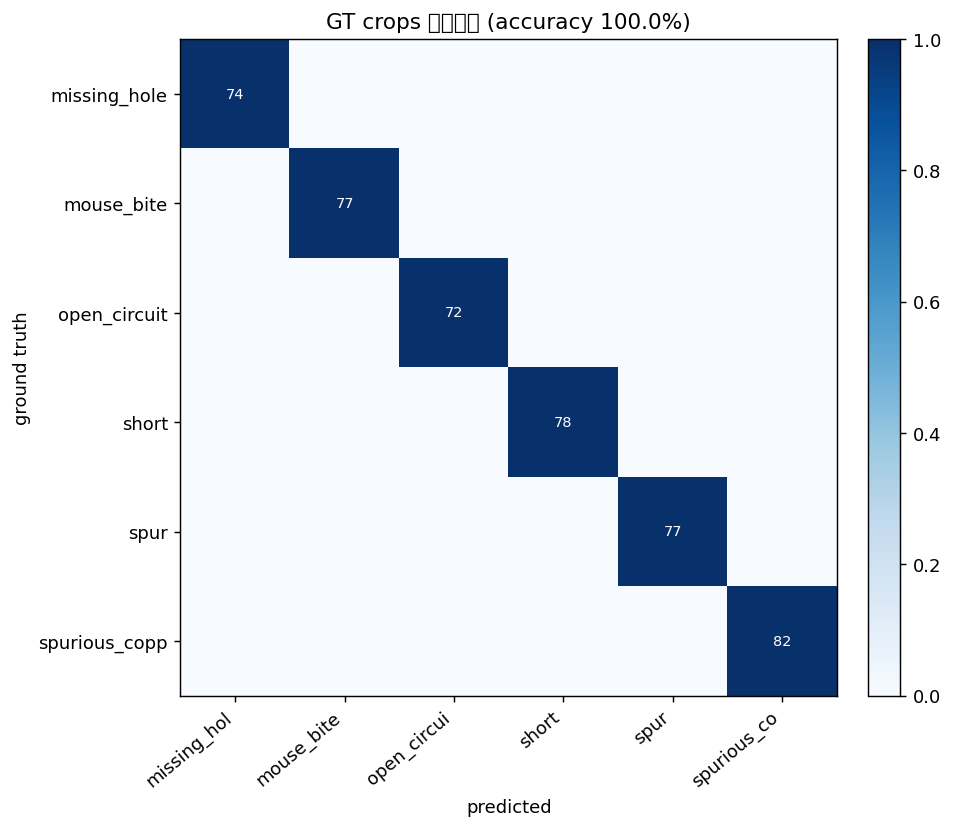

In [5]:
display(Image(filename=str(FIG / "02_confusion_matrix.png")))

### 4.2 End-to-end 混淆矩陣(CNN 在 Stage 1 proposals 上)

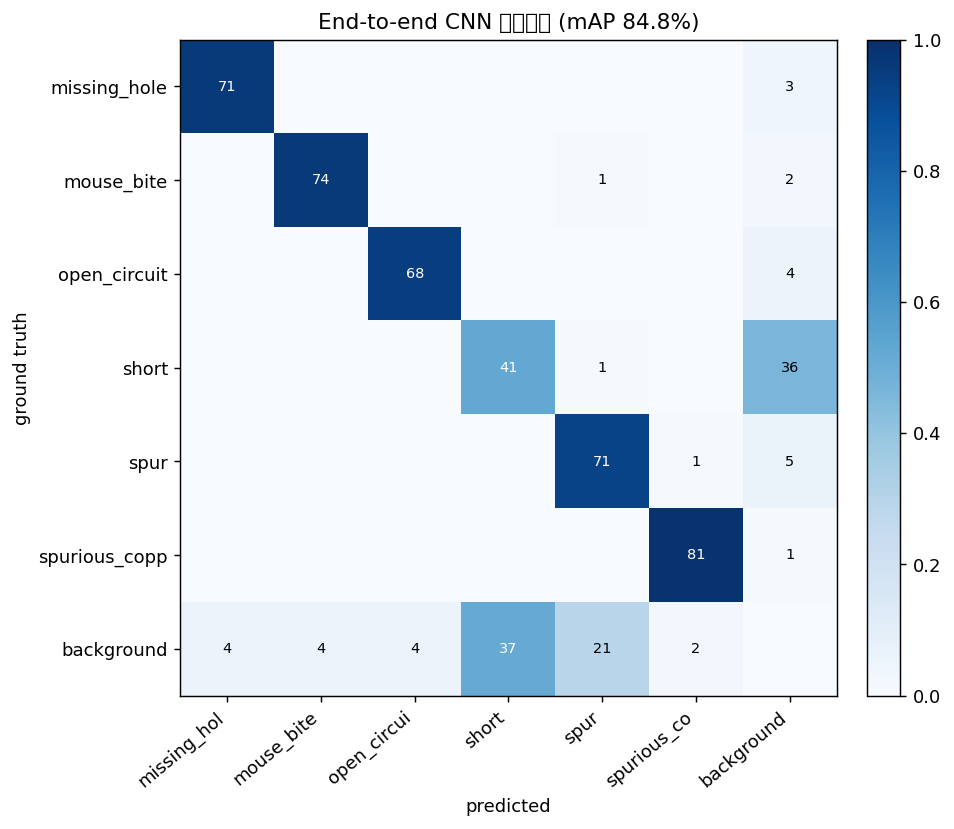

In [6]:
display(Image(filename=str(FIG / "02_end_to_end_confusion.png")))

### 4.3 樣本預測

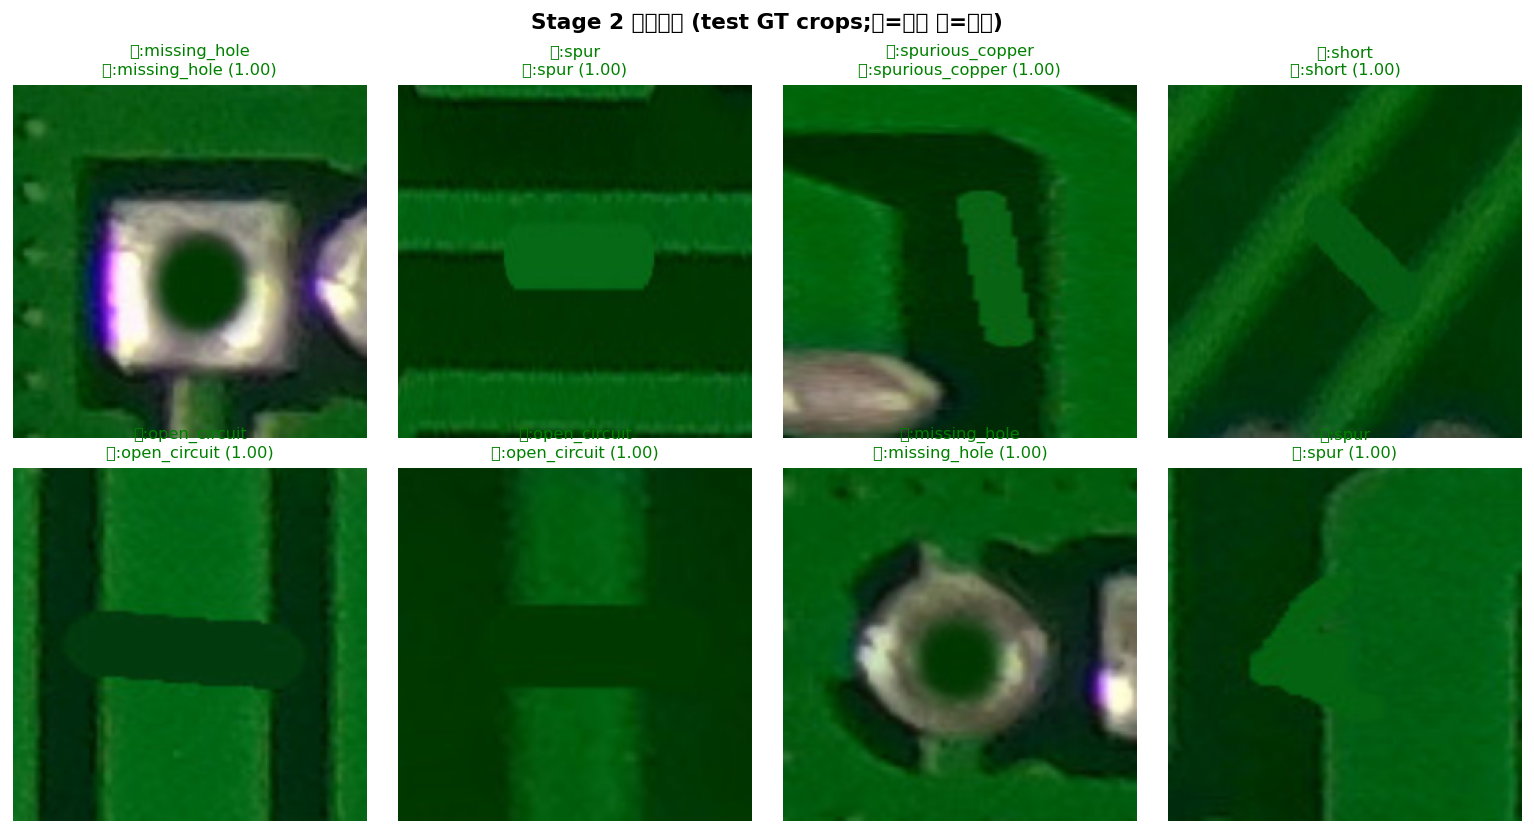

In [7]:
display(Image(filename=str(FIG / "02_sample_predictions.png")))

## 5. 失敗案例分析

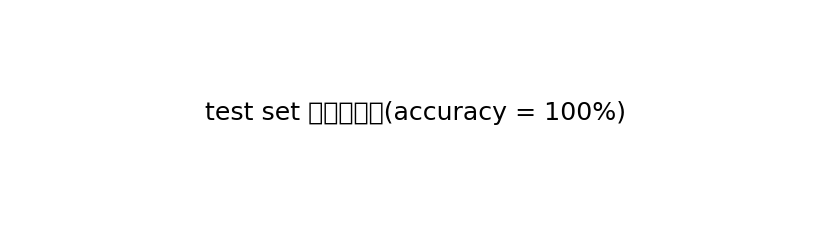

In [8]:
display(Image(filename=str(FIG / "02_misclassified_examples.png")))

完整分析見 [`results/dl_classifier_report.md`](../results/dl_classifier_report.md)。
重點:CNN 把 Stage 1 撞牆的小缺陷(`mouse_bite`/`open_circuit`/`spur`)從 AP 2–5%
拉到 90%+;唯一仍偏低的 `short` 是因為 **Stage 1 proposal 階段就漏抓**(recall
瓶頸),不是分類問題 —— 這正是 Stage 3(YOLO 端到端偵測)要解決的。